In [2]:
import os
from pathlib import Path
from typing import Literal, Optional, List

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-ana"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))
print(project_path/'data'/'df'/'test.df')

# My imports
from src.driver import AnalysisDriver
import src.branches as branches
from src.cuts import CutConfig, create_cut

/home/syebes/lambda-ana/data/df/test.df


# Load dfs

In [3]:
lambda_file = "/exp/sbnd/data/users/syebes/eafData/dfs/lambda.df"
aurora_file = "/exp/sbnd/data/users/syebes/eafData/dfs/aurora_gen2.df"

In [4]:
with pd.HDFStore(aurora_file, 'r') as store:
    print(store.keys())

['/cuts', '/hdr', '/mcnu', '/pot']


In [5]:
lambda_mcnu_df = pd.read_hdf(lambda_file, key='mcnu') # Each entry is a subrun
lambda_hdr_df = pd.read_hdf(lambda_file, key='hdr') # Each entry is an event
lambda_cuts_df = pd.read_hdf(lambda_file, key='cuts') # Each entry is an pfp
lambda_pot_df = pd.read_hdf(lambda_file, key='pot') # 

aurora_mcnu_df = pd.read_hdf(aurora_file, key='mcnu') # Each entry is a subrun
aurora_hdr_df = pd.read_hdf(aurora_file, key='hdr') # Each entry is an event
aurora_cuts_df = pd.read_hdf(aurora_file, key='cuts') # Each entry is an pfp
aurora_pot_df = pd.read_hdf(aurora_file, key='pot') # 

In [17]:
in_tpc_mask = ((aurora_mcnu_df.position.x > -200) &
              (aurora_mcnu_df.position.x < 200) &
              (aurora_mcnu_df.position.y > -200) &
              (aurora_mcnu_df.position.y < 200) &
              (aurora_mcnu_df.position.z > 0) &
              (aurora_mcnu_df.position.x < 500))

mask = (aurora_mcnu_df.n_lmbda > 0) & (aurora_mcnu_df.genie_mode > 0)
print(len(mask[mask & in_tpc_mask]))
print(len(aurora_mcnu_df[(aurora_mcnu_df.n_lmbda > 0) & in_tpc_mask]))

6892
7462


In [11]:
# How big is my lambda sample?

n_events = len(lambda_hdr_df)
n_signal_lambdas = len(lambda_cuts_df[lambda_cuts_df.is_lambda_signal].groupby(level=lambda_cuts_df.index.names[:-1]))

print(f'Number of simulated events: {n_events}')
print(f'Number of signal events: {n_signal_lambdas}')

Number of simulated events: 125751
Number of signal events: 84424


In [16]:
lambda_pot = lambda_pot_df.TotalPOT.sum()
aurora_pot = aurora_pot_df.TotalPOT.sum()

print(f'Lambda POT: {lambda_pot}')
print(f'Aurora POT: {aurora_pot}')

pot_3y = 7e20

lambda_scale = pot_3y / lambda_pot
aurora_scale = pot_3y / aurora_pot

aurora_sgnl_mask = (aurora_cuts_df.is_lambda_signal == 1) | (aurora_cuts_df.is_sigma0_signal == 1)

lambda_cuts_df['scale'] = pot_3y / (lambda_pot + aurora_pot)
aurora_cuts_df['scale'] = aurora_scale
aurora_cuts_df.loc[aurora_sgnl_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot)

Lambda POT: 1.428596135616784e+23
Aurora POT: 5.401777280854836e+20


In [17]:
# Concatenate

mcnu_df = pd.concat([lambda_mcnu_df, aurora_mcnu_df])
hdr_df = pd.concat([lambda_hdr_df, aurora_hdr_df])
cuts_df = pd.concat([lambda_cuts_df, aurora_cuts_df])
pot_df = pd.concat([lambda_pot_df, aurora_pot_df])

In [18]:
mask = cuts_df.bcfm_score == -9999
cuts_df.loc[mask, 'bcfm_score'] = -1

In [19]:
aurora_cuts_df

nu_score   bcfm_score  n_prim_pfps  \
__ntuple entry rec.slc..index                                       
0        0     0               0.456568     0.000001            1   
               1               0.536410     0.484421            2   
               2               0.528310     0.000001            4   
         1     0               0.592009     0.271403            3   
         2     0               0.437040     0.111127            2   
...                                 ...          ...          ...   
749261   11    1               0.528096     0.125803            1   
         12    0               0.518322     0.084115            1   
         13    0               0.493087     0.078057            1   
         14    0               0.439796 -9999.000000            3   
               1               0.488728     0.029550            1   

                               n_prim_trks  n_prim_shwrs  slc_in_fv  \
__ntuple entry rec.slc..index                                         
0        0     0                         1             0      False   
               1                         1             0       True   
               2                         0             3      False   
         1     0                         2             1       True   
         2     0                         2             0       True   
...                                    ...           ...        ...   
749261   11    1                         1             0       True   
         12    0                         1             0       True   
         13    0                         1             0      False   
         14    0                         2             1       True   
               1                         1             0       True   

                               n_trks_exit  n_shwrs_exit   max_gap  \
__ntuple entry rec.slc..index                                        
0        0     0                         0             0  0.000000   
               1                         0             0  0.000000   
               2                         0             0  4.751028   
         1     0                         1             0  1.783951   
         2     0                         0             0  0.473345   
...                                    ...           ...       ...   
749261   11    1                         0             0  0.000000   
         12    0                         0             0  0.000000   
         13    0                         0             0  0.000000   
         14    0                         1             0  4.655983   
               1                         1             0  0.000000   

                               slc_tmatch_idx  genie_mode  is_lambda_signal  \
__ntuple entry rec.slc..index                                                 
0        0     0                         -999          -1             False   
               1                            3          10             False   
               2                         -999          -1             False   
         1     0                            0          10             False   
         2     0                            0           0             False   
...                                       ...         ...               ...   
749261   11    1                            0           0             False   
         12    0                            1           0             False   
         13    0                            0           1             False   
         14    0                         -999          -1             False   
               1                            0           0             False   

                               is_sigma0_signal    scale  
__ntuple entry rec.slc..index                             
0        0     0                          False  1.29587  
               1                          False  1.29587  
               2                  

# Define config parameters

In [8]:
import yaml

with open("../../config/cuts_config.yaml", "r") as f:
    config = yaml.safe_load(f)

In [9]:
cuts_config = []

for cut_cfg in config['preselection_cuts'].values():
    cfg = CutConfig(
        cut = create_cut(cut_cfg['cut']),
        **{k: v for k, v in cut_cfg.items() if k != "cut"}
    )

    cuts_config.append(cfg)

In [10]:
driver = AnalysisDriver(cuts_df, cuts_config)

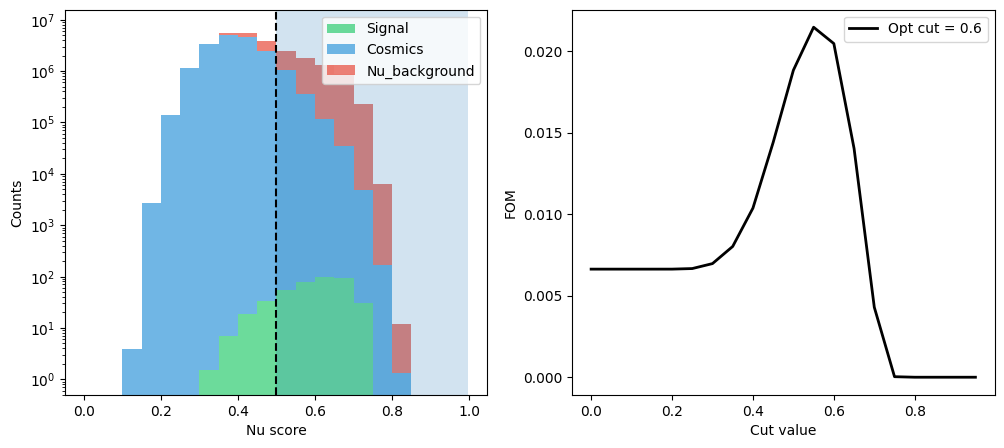

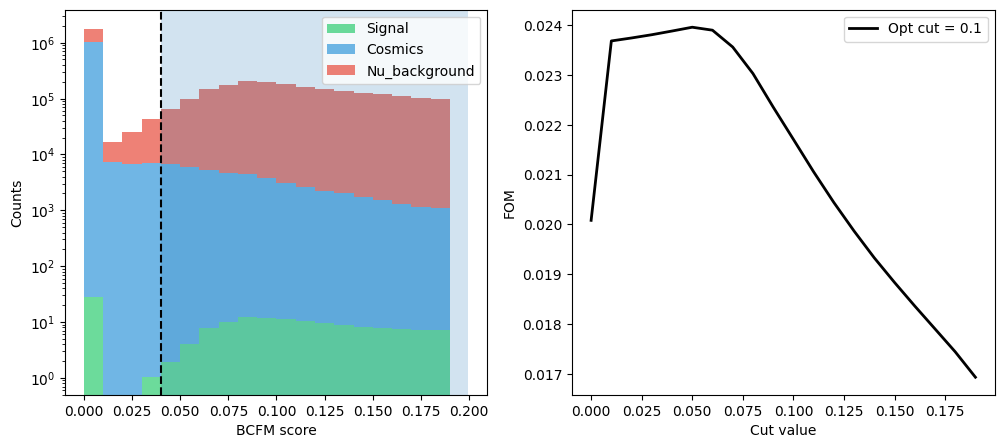

/home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/matplotlib/axes/_axes.py:7117: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  bins = np.histogram_bin_edges(
/home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/matplotlib/axes/_axes.py:7132: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  m, bins = np.histogram(x[i], bins, weights=w[i], **hist_kwargs)


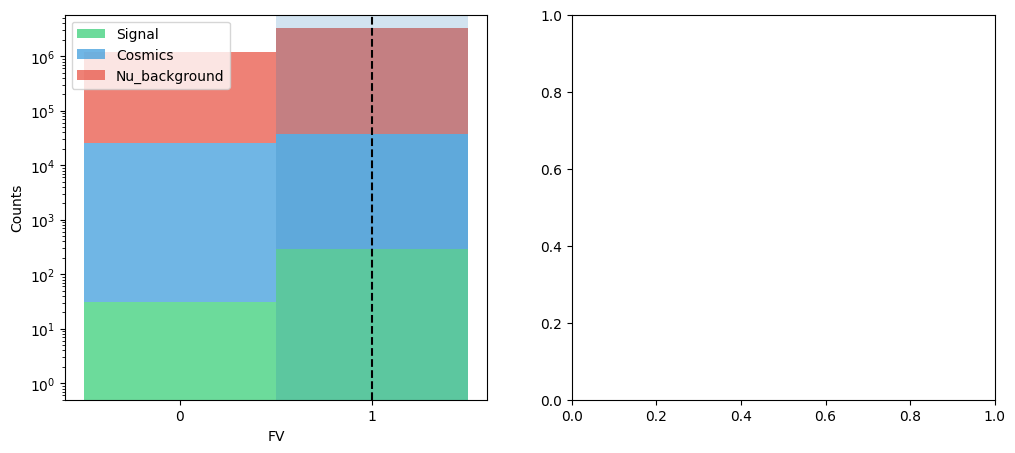

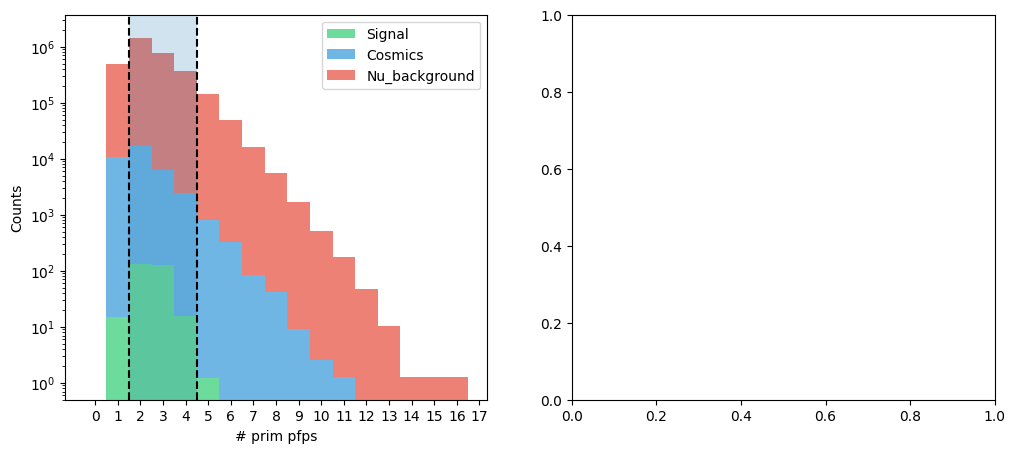

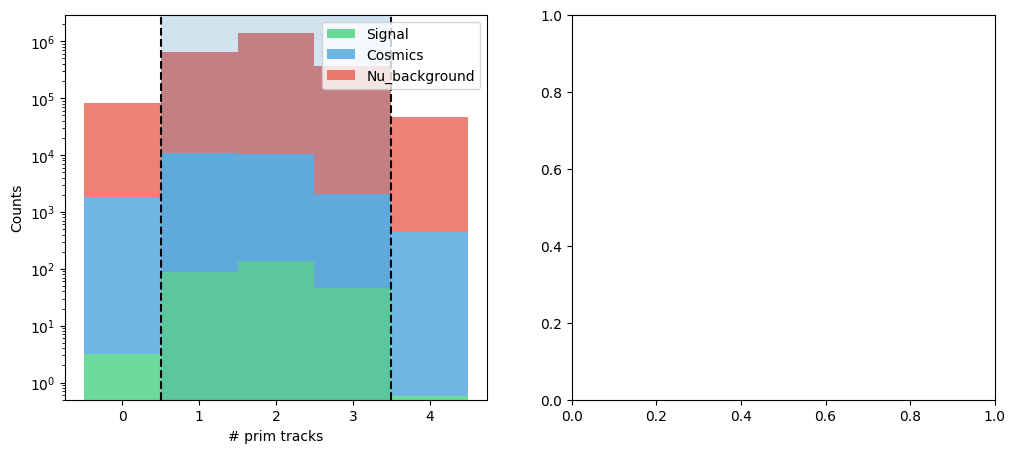

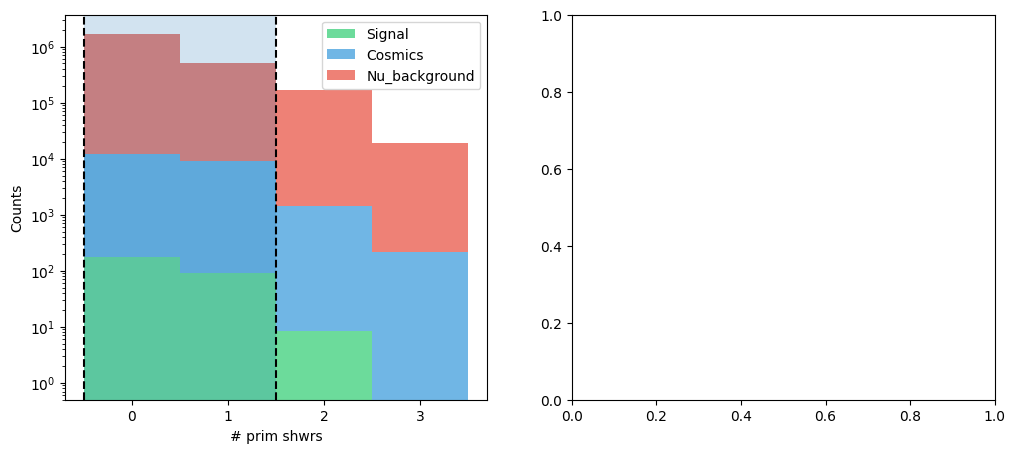

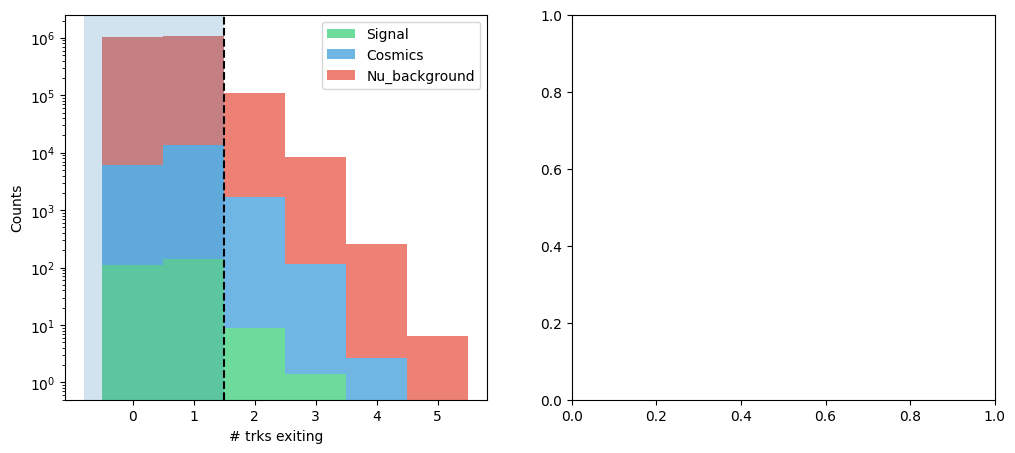

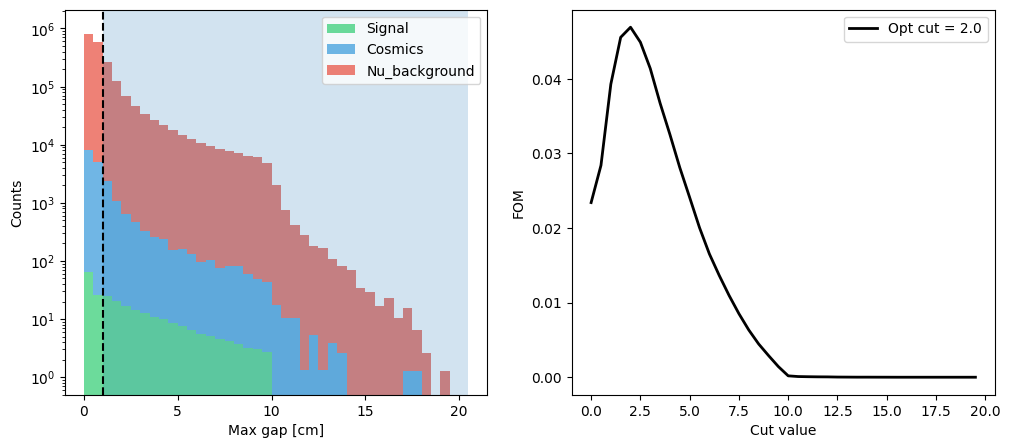

,Stage,Cut value,Signal,Cosmics,Nu_background,Cut efficiency (%),Total efficiency (%),Purity (%),Cut bck rejection (%),Total bck rejection (%)
0,Initial,-,416.8,1.8e+07,7.7e+06,100,100.0,0.00,0.0,0.0
1,Nu score,>= 0.5,356.2,1.6e+06,5.2e+06,85.47,85.47,0.01,74.28,74.2800
2,BCFM score,>= 0.04,324.9,6.3e+04,4.4e+06,91.21,77.96,0.01,34.39,83.1262
3,FV,== 1,293.4,3.7e+04,3.2e+06,90.32,70.41,0.01,26.59,87.6134
4,# prim pfps,"[2, 4]",277.4,2.5e+04,2.5e+06,94.53,66.56,0.01,21.88,90.3240
5,# prim tracks,"[1, 3]",273.6,2.3e+04,2.4e+06,98.64,65.66,0.01,5.08,90.8156
6,# prim shwrs,"[0, 1]",264.8,2.1e+04,2.2e+06,96.78,63.54,0.01,7.87,91.5386
7,# trks exiting,< 2,254.7,1.9e+04,2.1e+06,96.16,61.10,0.01,5.34,91.9908
8,Max gap [cm],> 1,165.1,6.3e+03,6.9e+05,64.83,39.62,0.02,66.94,97.3521


In [11]:
driver.plot_cuts()
driver.get_cuts_performance(print_initial = True)